# Roller on raceway: subsurface stresses of the line contact, SlipPY `SubsurfaceStress` against Johnson

**Case:** `validation/contact/hertz_line_subsurface` (V-SUB-02), criteria L2-L4 of the README.

The line contact is solved once on the default grid of the bridge (periodic along the roller
axis, as `slippy_bridge.contact.static_step.run` sets it), with SlipPY's `SubsurfaceStress` on
body 1, periodic on the same axis (`periodic_axes=(False, True)`), depths $0 \le z \le 2a$, step
$0.02a$. The model is built here with SlipPY directly (José, Q2); the surfaces come from
`slippy_bridge.contact.pair`. $a$ (Johnson's semi-width) and $p_0$ are those of
`references.contact.hertz.hertz_line`; SlipPY's own line-contact stress functions are not used
(open sign issue in `_stress_line_contact`).

- **L2** $\tau_1 = (\sigma_1 - \sigma_3)/2$ on the axis: max and depth against $0.300 p_0$ at
  $0.785a$ (Table 4.1) and against Johnson's axis formula evaluated directly,
  $\tau_1/p_0 = \zeta - \zeta^2(1+\zeta^2)^{-1/2}$, $\zeta = z/a$ (text after Eq. (4.46), PDF 112;
  magnitude).
- **L3** $\tau_{zx}$: max and position against $0.25 p_0$ at $(\pm0.87a, 0.50a)$ (PDF 299).
- **L4** Appendix 4 (PDF 439-440): $-\sigma_x/p_0$, $-\sigma_z/p_0$ and $|\tau_{zx}|/p_0$ at the
  printed $(x/a, z/a)$, the BEM field interpolated linearly along $x$ ($x \ge 0$; the tables print
  magnitudes, the sign of $\tau_{zx}$ follows the sign of $x$).

L2 needs the principal stresses, L3-L4 the tensor: two models, one per request.

**Solve protocol** (José, 2026-10-16), per model: attempt 1 `model.solve()` as is; if it raises,
the traceback and the SlipPY log are saved and the model is rebuilt with a new name; attempt 2
`solve(skip_data_check=True)`; attempt 3 the same with SlipPY's own switch
`slippy.ERROR_IF_MISSING_SUB_MODEL = False` (restored afterwards). Attempts 1-2 are José's
protocol; attempt 3 is a diagnostic beyond it (SlipPY's own switch, named in its error message;
no SlipPY change; José to confirm whether it counts), and a criterion graded on its field says
so. Every outcome is recorded; a FAIL of the field carries "suspected SlipPY defect, not fixed".
Nothing in SlipPY is worked around. `--smoke` has no effect (one default grid already).

In [1]:
import math
import shutil
import time
import traceback

import matplotlib.pyplot as plt
import numpy as np
import slippy
import slippy.contact as c
from axisforge.outputs._format import format_table, read_records_csv, write_records_csv
from slippy.contact.sub_models import SubsurfaceStress

from references.contact.hertz import hertz_line, hertz_line_stress
from slippy_bridge.contact import Grid, pair
from validation._support.figures import contact_plots
from validation._support.style import use_style

from construction import CASE, RESULTS, Z_OVER_A

use_style()                                       # house paper style (style/README.md)

NAME = "02_subsurface"
SLIPPY_OUT = RESULTS / "slippy_subsurface"
SLIPPY_OUT.mkdir(parents=True, exist_ok=True)                       # git-ignored (D-0020)
REFERENCE = RESULTS.parent / "reference_values.csv"                 # the printed rows, copied unchanged

JUDGE = hertz_line(CASE.r1, CASE.r2, CASE.E, CASE.nu, CASE.load)
A, P0 = JUDGE["s_x_m"], JUDGE["p0_Pa"]                              # semi-width [m], max pressure [Pa]
GRID = Grid.around(CASE)                                            # default grid of the bridge
LOAD = CASE.load * GRID.X.shape[1] * GRID.h                         # [N/m] x periodic length [m] = [N]

## 1. Models and solve protocol

In [2]:
# CSV labels (UTF-8 files; the console prints ASCII only)
SLIPPY_DEFECT = "suspected SlipPY defect, not fixed (José, 2026-10-16)"
ATTEMPT_3 = ("attempt 3: beyond the ruling's two attempts; SlipPY's own switch named in its error message; "
             "no SlipPY change; José to confirm whether it counts")
ATTEMPTS = ((1, "solve()", {}, False, "ruling (José)"),
            (2, "solve(skip_data_check=True)", {"skip_data_check": True}, False, "ruling (José)"),
            (3, "solve(skip_data_check=True), ERROR_IF_MISSING_SUB_MODEL=False", {"skip_data_check": True}, True,
             ATTEMPT_3))


def solve(components, tag):
    """Build and solve the model with SubsurfaceStress(``components``) by the protocol.

    The step arguments are those of ``slippy_bridge.contact.static_step.run`` for a line contact
    (method "pk", tolerance 1e-9, periodic along axis 1, the load over the periodic length).

    Returns
    -------
    state : dict or None
        SlipPY's final state, None if every attempt raised.
    outcomes : list of dict
        One record per attempt.
    """
    outcomes = []
    for attempt, call, kwargs, switch_off, note in ATTEMPTS:
        s1, s2 = pair(CASE, GRID)
        model = c.ContactModel(f"{CASE.label}_{tag}_{attempt}_{time.time_ns()}", s1, s2,   # new name each time
                               output_dir=str(SLIPPY_OUT))
        step = c.StaticStep("static", normal_load=LOAD, method="pk", tolerance=1e-9,
                            periodic_geometry=True, periodic_axes=(False, True))
        model.add_step(step)
        step.add_sub_model(SubsurfaceStress(z=Z_OVER_A * A, surface=1, periodic_axes=(False, True),
                                            stress_components=components))
        saved = slippy.ERROR_IF_MISSING_SUB_MODEL
        t0 = time.perf_counter()
        try:
            if switch_off:
                slippy.ERROR_IF_MISSING_SUB_MODEL = False
            state = model.solve(**kwargs)
            outcomes.append({"model": tag, "attempt": attempt, "call": call, "outcome": "solved", "error": "",
                             "note": note, "wall_s": time.perf_counter() - t0})
            return state, outcomes
        except Exception as exc:                                    # recorded, never fixed here
            (RESULTS / f"{NAME}_{tag}_traceback_{attempt}.txt").write_text(traceback.format_exc(), encoding="utf-8")
            log = SLIPPY_OUT / f"{model.name}.log"
            if log.is_file():
                shutil.copyfile(log, RESULTS / f"{NAME}_{tag}_attempt_{attempt}.log")
            outcomes.append({"model": tag, "attempt": attempt, "call": call, "outcome": "raised", "note": note,
                             "error": f"{type(exc).__name__}: {str(exc).splitlines()[0]}",
                             "wall_s": time.perf_counter() - t0})
        finally:
            slippy.ERROR_IF_MISSING_SUB_MODEL = saved
    return None, outcomes


principal, outcomes_p = solve(("1", "3"), "principal")
tensor, outcomes_t = solve(("all",), "tensor")
outcomes = outcomes_p + outcomes_t
print(format_table((("model", "model", "s"), ("attempt", "attempt", ".0f"), ("call", "call", "s"),
                    ("outcome", "outcome", "s"), ("wall_s", "t [s]", ".2f"), ("error", "error", "s")), outcomes))

    model  attempt                                                           call  outcome  t [s]                                                                                                               error
---------  -------  -------------------------------------------------------------  -------  -----  ------------------------------------------------------------------------------------------------------------------
principal        1                                                        solve()   raised   0.27                   ValueError: Step static dosn't provide what it should or provides things which are not declared, 
principal        2                                    solve(skip_data_check=True)   raised   1.24  ValueError: Sub model sub_surface_stress dosn't provide what it should or provides things which are not declared, 
principal        3  solve(skip_data_check=True), ERROR_IF_MISSING_SUB_MODEL=False   solved   0.23                                               

## 2. Johnson's axis formula and the Appendix 4 rows

The axis formula is evaluated by `references.contact.hertz.hertz_line_stress` (McEwen's field at
$x = 0$, equal to the formula to round-off; tested in `tests/test_contact_reference.py`).

In [3]:
zeta_fine = np.linspace(0.0, 2.0, 200001)                           # step 1e-5 a
tau_fine = hertz_line_stress(0.0 * zeta_fine, zeta_fine)["tau1_over_p0"]   # tau1/p0 on the axis
TAU_EQ, Z_EQ = float(tau_fine.max()), float(zeta_fine[tau_fine.argmax()])
print(f"axis formula: tau1 max {TAU_EQ:.5f} p0 at z = {Z_EQ:.5f} a")

rows = read_records_csv(REFERENCE, text_fields=("case_id", "kind", "quantity", "symbol", "value", "unit",
                                                "condition", "source_key", "location", "read_from", "note"))
# Appendix 4 p-tables: table 1 -(sigma_x)_p/p0, table 2 -(sigma_z)_p/p0, table 3 -/+(tau_zx)_p/p0
APPENDIX = {"Appendix 4, table 1": "-sigma_x/p0", "Appendix 4, table 2": "-sigma_z/p0",
            "Appendix 4, table 3": "|tau_zx|/p0"}
points = []
for r in rows:
    if r["location"] in APPENDIX:
        z_tag, x_tag = r["condition"].split(";")                    # "z/a=0.2", "x/a=+-0.4"
        points.append({"quantity": APPENDIX[r["location"]], "z_over_a": float(z_tag.split("=")[1]),
                       "x_over_a": float(x_tag.split("=+-")[1]), "printed": float(r["value"])})

axis formula: tau1 max 0.30028 p0 at z = 0.78615 a


## 3. Criteria

The axis is node row $n_x/2$ (the grid centre is the contact centre); along the roller axis every
column is the same (periodic), column $n_y/2$ is read. Tolerances: README L2-L4 (**[proposed]**
for L2, L3).

In [4]:
def row(cid, quantity, value, expected, limit, ok, note=""):
    """One criteria record; err is value - expected, ratio value/expected; ok None means recorded, not graded.

    A FAIL of a SlipPY field carries the defect label after ``note``.
    """
    return {"id": cid, "quantity": quantity, "value": value, "expected": expected, "err": value - expected,
            "ratio": value / expected if expected else math.nan, "limit": limit,
            "result": "recorded" if ok is None else ("PASS" if ok else "FAIL"),
            "note": "; ".join(s for s in (note, SLIPPY_DEFECT if ok is not None and not ok else "") if s)}


def graded_on(outcomes):
    """Which attempt gave the field, for the criteria notes (attempt 3 is a diagnostic)."""
    attempt = outcomes[-1]["attempt"]
    return f"graded on attempt {attempt}" + (" (diagnostic)" if attempt == 3 else "")


i0, j0 = GRID.X.shape[0] // 2, GRID.X.shape[1] // 2
x_over_a = GRID.X[:, j0] / A                                        # node positions along rolling [-]
criteria, profile = [], []
BLOCKED = f"blocked: {SLIPPY_DEFECT}; tracebacks {NAME}_<model>_traceback_*.txt"
if principal is None:
    criteria.append(row("L2", "tau1 max and depth (no field: every attempt raised)", math.nan, math.nan, "-", None,
                        BLOCKED.replace("<model>", "principal")))
else:
    s1, s3 = np.asarray(principal["surface_1_1"]), np.asarray(principal["surface_1_3"])   # (z, x, y) [Pa]
    tau_axis = 0.5 * (s1[:, i0, j0] - s3[:, i0, j0]) / P0
    k = int(np.nanargmax(tau_axis))
    tau_eq = hertz_line_stress(0.0 * Z_OVER_A, Z_OVER_A)["tau1_over_p0"]
    profile = [{"z_over_a": z, "tau1_over_p0": t, "tau1_eq_over_p0": te, "ratio": t / te if te else math.nan}
               for z, t, te in zip(Z_OVER_A, tau_axis, tau_eq)]
    k_eq = int(np.argmin(abs(Z_OVER_A - Z_EQ)))
    graded = graded_on(outcomes_p)
    print("L2", graded)
    criteria += [
        row("L2", "tau1 max / p0 (Table 4.1) [proposed]", tau_axis[k], 0.300, "+-0.005",
            abs(tau_axis[k] - 0.300) <= 0.005, graded),
        row("L2", "depth of tau1 max / a (Table 4.1) [proposed]", Z_OVER_A[k], 0.785, "+-0.01",
            abs(Z_OVER_A[k] - 0.785) <= 0.01, graded),
        row("L2", "tau1 max / p0 (axis formula) [proposed]", tau_axis[k], TAU_EQ, "+-0.005",
            abs(tau_axis[k] - TAU_EQ) <= 0.005, graded),
        row("L2", "depth of tau1 max / a (axis formula) [proposed]", Z_OVER_A[k], Z_EQ, "+-0.01",
            abs(Z_OVER_A[k] - Z_EQ) <= 0.01, graded),
        row("L2", f"tau1 / p0 at z = {Z_OVER_A[k_eq]:.2f} a (axis formula, field ratio)", tau_axis[k_eq], tau_eq[k_eq],
            "-", None, graded),
    ]
if tensor is None:
    for cid, q in (("L3", "tau_zx max and position"), ("L4", "Appendix 4 p-tables")):
        criteria.append(row(cid, q + " (no field: every attempt raised)", math.nan, math.nan, "-", None,
                            BLOCKED.replace("<model>", "tensor")))
else:
    fields = {"-sigma_x/p0": -np.asarray(tensor["surface_1_xx"])[:, :, j0] / P0,
              "-sigma_z/p0": -np.asarray(tensor["surface_1_zz"])[:, :, j0] / P0,
              "|tau_zx|/p0": np.abs(np.asarray(tensor["surface_1_xz"])[:, :, j0]) / P0}   # (z, x)
    tau_zx = fields["|tau_zx|/p0"]
    kz, kx = np.unravel_index(int(np.nanargmax(tau_zx)), tau_zx.shape)
    graded = graded_on(outcomes_t)
    criteria += [
        row("L3", "tau_zx max / p0 [proposed]", tau_zx[kz, kx], 0.25, "+-0.005",
            abs(tau_zx[kz, kx] - 0.25) <= 0.005, graded),
        row("L3", "|x| of tau_zx max / a [proposed]", abs(x_over_a[kx]), 0.87, "+-0.01",
            abs(abs(x_over_a[kx]) - 0.87) <= 0.01, graded),
        row("L3", "z of tau_zx max / a [proposed]", Z_OVER_A[kz], 0.50, "+-0.01",
            abs(Z_OVER_A[kz] - 0.50) <= 0.01, graded),
    ]
    right = x_over_a >= 0.0                                         # the printed columns are +-x/a: x >= 0 side
    for pt in points:
        # every printed depth is a node depth; z/a = 0 is read at Z_OVER_A[0] (construction.py)
        (kz,) = np.flatnonzero(np.isclose(Z_OVER_A, pt["z_over_a"], rtol=0.0, atol=1e-3))
        pt["bem"] = float(np.interp(pt["x_over_a"], x_over_a[right], fields[pt["quantity"]][kz, right]))
        pt["diff"] = pt["bem"] - pt["printed"]
    worst = max(points, key=lambda pt: abs(pt["diff"]))
    n_fail = sum(abs(pt["diff"]) > 0.001 for pt in points)
    criteria.append(row("L4", f"Appendix 4: worst of {len(points)} points ({worst['quantity']} at "
                              f"x/a {worst['x_over_a']:g}, z/a {worst['z_over_a']:g}); {n_fail} beyond 0.001",
                        worst["bem"], worst["printed"], "+-0.001", n_fail == 0, graded))

print(format_table((("id", "ID", "s"), ("quantity", "quantity", "s"), ("value", "value", ".5g"),
                    ("expected", "expected", ".5g"), ("err", "err", "+.3e"), ("ratio", "ratio", ".3e"),
                    ("limit", "limit", "s"), ("result", "result", "s")), criteria))
write_records_csv(RESULTS / f"{NAME}.csv", outcomes + profile + (points if tensor is not None else []))
write_records_csv(RESULTS / f"{NAME}_criteria.csv", criteria)

L2 graded on attempt 3 (diagnostic)
ID                                                  quantity       value  expected         err      ratio    limit    result
--  --------------------------------------------------------  ----------  --------  ----------  ---------  -------  --------
L2                      tau1 max / p0 (Table 4.1) [proposed]   1.097e-05       0.3  -3.000e-01  3.657e-05  +-0.005      FAIL
L2              depth of tau1 max / a (Table 4.1) [proposed]        0.34     0.785  -4.450e-01  4.331e-01   +-0.01      FAIL
L2                   tau1 max / p0 (axis formula) [proposed]   1.097e-05   0.30028  -3.003e-01  3.653e-05  +-0.005      FAIL
L2           depth of tau1 max / a (axis formula) [proposed]        0.34   0.78615  -4.461e-01  4.325e-01   +-0.01      FAIL
L2       tau1 / p0 at z = 0.78 a (axis formula, field ratio)  5.3167e-06   0.30028  -3.003e-01  1.771e-05        -  recorded
L3  tau_zx max and position (no field: every attempt raised)           -         -       

## 4. Figures: the closed-form field

Johnson's line-contact stresses (McEwen) on the axis against depth, with the Table 4.1 value as
an open marker, and the contours of $\tau_1/p_0$ in the $x$-$z$ plane. The SlipPY subsurface field
is not drawn (OPEN R-268, R-269). Written to `results/02_subsurface_depth.png` and
`results/02_subsurface_contours.png`.

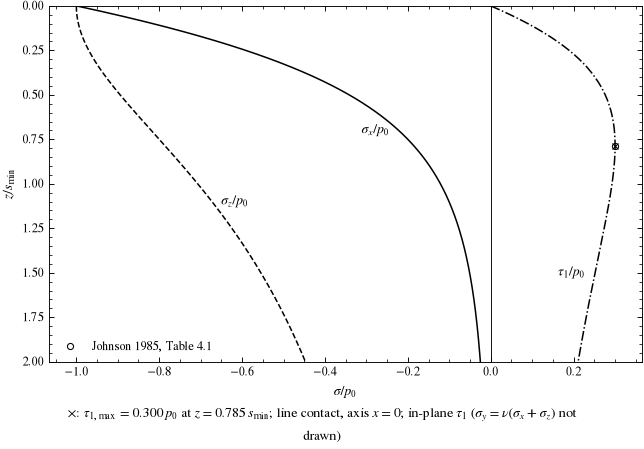

In [5]:
z_plot = np.linspace(0.0, 2.0, 401)                                 # depth / a [-]
fig = contact_plots.subsurface_depth(z_plot, hertz_line_stress(0.0 * z_plot, z_plot),
                                     published=[(0.300, 0.785, "Johnson 1985, Table 4.1")],
                                     note=r"line contact, axis $x = 0$; in-plane $\tau_1$ "
                                          r"($\sigma_y = \nu(\sigma_x + \sigma_z)$ not drawn)")
fig.savefig(RESULTS / f"{NAME}_depth.png")
plt.close(fig)                                    # shown once, by the line below
fig

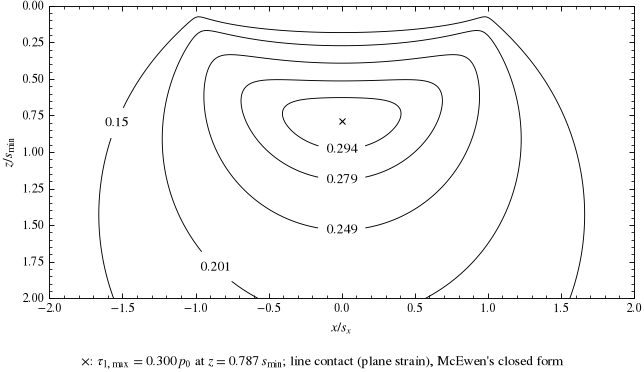

In [6]:
x_grid, z_grid = np.linspace(-2.0, 2.0, 401), np.linspace(0.0, 2.0, 301)   # x / a, z / a [-]
tau1_xz = hertz_line_stress(*np.meshgrid(x_grid, z_grid))["tau1_over_p0"]  # rows = depth
fig = contact_plots.subsurface_contours(x_grid, z_grid, tau1_xz,
                                        note="line contact (plane strain), McEwen's closed form")
fig.savefig(RESULTS / f"{NAME}_contours.png")
plt.close(fig)                                    # shown once, by the line below
fig